In [1]:
import numpy as np
from math import exp, log
import json
from scipy.integrate import solve_ivp

with open('materiais.json', 'r') as materiais:
    componentes = json.load(materiais)

In [2]:
def SRK(massa, massa_total, temperatura, pressão, componentes):
        
    y = {}
    for componente in componentes:
        y[componente] = massa[componente]/massa_total
    
    R = 8.314 # J/mol.K

    alfa = {}
    aci = {}
    ai = {}
    bi = {}

    for componente in componentes:
        alfa[componente]=(1+(0.480+(1.574*componentes[componente]["w"])-(0.176*componentes[componente]["w"]**2))*(1-((temperatura/componentes[componente]["Tc"])**0.5)))**2
        aci[componente]=0.42748*(((R**2)*(componentes[componente]["Tc"]**2.5))/componentes[componente]["Pc"])
        ai[componente]=alfa[componente]*aci[componente]
        bi[componente]=0.008664*R*componentes[componente]["Tc"]/componentes[componente]["Pc"]
    
    #Regra de mistura
    aij = {}
    a_mix = 0
    b_mix = 0
    for componente1 in componentes:
        for componente2 in componentes:
            aij[(componente1, componente2)] = y[componente1]*y[componente2]*((ai[componente1]*ai[componente2])**0.5) #* (1 - kij.get((i, j), kij.get((j, i), 0))) - parametro considerado 0 por simplificação
            a_mix += aij[(componente1, componente2)] 
        b_mix += y[componente1]*bi[componente1]

    
    A=(a_mix*pressão)/((R**2)*(temperatura**2))
    B=(b_mix*pressão)/(R*temperatura)
    
    #coeffs = [1, -(1 - B), A - 2*B - 3*B**2, -(A*B - B**2 - B**3)]
    coeffs = [1, -1, (A - B - B**2), -(A * B)]
    Z_roots = np.roots(coeffs)
    Z_reais = np.real(Z_roots[np.isreal(Z_roots)])
    Z = max(Z_reais)

    return alfa, aci, ai, bi, aij, a_mix, b_mix, A, B, Z

In [3]:
def fugacidade(massa, massa_total, parametros, componentes):
    y = {}
    for componente in componentes:
        y[componente] = massa[componente]/massa_total
    
    phi = {}
    for componente1 in componentes:
        term1 = parametros["bi"][componente1] * (parametros["Z"] - 1) / parametros["b_mix"]
        term2 = np.log(parametros["Z"] - parametros["B"])
        term3 = parametros["A"] / parametros["B"]
        sum_term4 = 0
        for componente2 in componentes:
            sum_term4 += y[componente2]*np.sqrt(parametros["ai"][componente1]*parametros["ai"][componente2])
        
        term4 = (2* sum_term4)/parametros["a_mix"]
        term5 = np.log((parametros["Z"]+parametros["B"])/parametros["Z"])
        ln_phi_i = term1 - term2 - term3 * (term4 - (parametros["bi"][componente1]/parametros["b_mix"]))*term5
        phi[componente1] = np.exp(ln_phi_i)
    
    return phi

In [4]:
def capacidade_calorífica(componentes, temperatura):
    R = 8.314
    cp = {}
    for componente, constantes in componentes.items():
        cp[componente] = R*(constantes["A"]+(constantes["B"]*temperatura)+(constantes["C"]*(temperatura**2))+(constantes["D"]*(temperatura**-2))+(constantes["E"]*(temperatura**3)))

    return cp

In [5]:
def volume_SRK(pressao, temperatura, parametros):
    R = 8.314

    coef1 = pressao
    coef2 = -(R * temperatura)
    coef3 = pressao * parametros["b_mix"] - R * temperatura * parametros["b_mix"] - parametros["a_mix"]
    coef4 = -parametros["a_mix"] * parametros["b_mix"]

    # Coeficientes do polinômio cúbico
    coeficientes = [coef1, coef2, coef3, coef4]
    
    # Encontrar as raízes do polinômio cúbico
    roots = np.roots(coeficientes)
    
    # Filtrar as raízes reais e positivas
    real_roots = [root for root in roots if np.isreal(root) and root > 0]
    
    if len(real_roots) == 0:
        raise ValueError("Não foram encontradas raízes reais e positivas.")
    
    # Retornar a menor raiz real e positiva
    return np.real(min(real_roots))

In [6]:
def viscosidade(componentes, massa, massa_total,temperatura):
    y = {}
    visc = {}
    visc_mix = 0

    for componente in componentes:
        y[componente] = massa[componente]/massa_total
        visc[componente] = (componentes[componente]["constantes_de_viscosidade"][0]*(temperatura**componentes[componente]["constantes_de_viscosidade"][1]))/(1+(componentes[componente]["constantes_de_viscosidade"][2]/temperatura)+(componentes[componente]["constantes_de_viscosidade"][3]/temperatura**2))
        visc_mix += y[componente]*visc[componente]

    return visc_mix

In [7]:
def cinetica(vazao_molar, componentes):
    temperatura = vazao_molar["T"]
    pressao = vazao_molar["P"]
    vazao_molar_total = sum(vazao_molar.values())
    vazao_massica = {}
    for componente in componentes:
        vazao_massica[componente] = componentes[componente]["MM"] * vazao_molar[componente]

    vazao_massica_total = sum(vazao_massica.values())
    
    alfa, aci, ai, bi, aij, a_mix, b_mix, A, B, Z = SRK(vazao_massica, vazao_massica_total, temperatura, pressao, componentes)
    parametros = {
        "alfa" : alfa,
        "aci" : aci,
        "ai" : ai,
        "bi" : bi,
        "aij" : aij,
        "a_mix" : a_mix,
        "b_mix" : b_mix,
        "A" : A,
        "B" : B,
        "Z" : Z
    }

    vazao_volumetrica = (vazao_molar_total * 8.314 * parametros["Z"] * temperatura)/pressao

    rt=8.314*temperatura
    ka=1.88e8*exp(-113711/rt)
    kb=1.16e10*exp(-126523/rt)
    kc=7.08e4*exp(-68252/rt)
    KH2O=3.8e-10*exp(80876/rt)
    Kpa=exp((1.183e4/temperatura)-26.061)
    Kpb=exp((-4.773e3/temperatura)+4.672)
    Kpc=Kpa*Kpb;
    KCO=7.99e-7*exp(58700/rt)
    KCO2=1.02e-7*exp(68000/rt)
    RKH2=KH2O/(5.64e-11*exp(105600/rt))

    phi=fugacidade(vazao_massica, vazao_massica_total, parametros, componentes)
    pressoes_parciais = {}

    for componente in componentes:
        pressoes_parciais[componente] = phi[componente]*(vazao_molar[componente]*rt)/(101325*vazao_volumetrica)

    r1=(ka*KCO*((pressoes_parciais["CO"]*(pressoes_parciais["H2"]**1.5))-(pressoes_parciais["CH3OH"]/(Kpa*(pressoes_parciais["H2"]**0.5)))))/((1+(KCO*pressoes_parciais["CO"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))
    r2=(kb*KCO2*((pressoes_parciais["CO"]*pressoes_parciais["H2"])-((pressoes_parciais["CO"]*pressoes_parciais["H2O"])/Kpb)))/((1+(KCO2*pressoes_parciais["CO2"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))
    r3=(kc*KCO2*((pressoes_parciais["CO2"]*(pressoes_parciais["H2"]**1.5))-((pressoes_parciais["H2O"]*pressoes_parciais["CH3OH"])/(Kpc*(pressoes_parciais["H2"]**1.5)))))/((1+(KCO2*pressoes_parciais["CO2"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))

    taxa_de_geração = {}

    taxa_de_geração["CO"] = (-r1)+(r2)
    taxa_de_geração["H2"]=(-2*r1)+(-r2)+(-3*r3)
    taxa_de_geração["CH3OH"]=(r1+r3)
    taxa_de_geração["CH4"]=(0)
    taxa_de_geração["H2O"]=(r2+r3)
    taxa_de_geração["CO2"]=(-r2)+(-r3)
    taxa_de_geração["N2"]=0

    # == BALANÇO DE ENERGIA ==
    # entalpias padrão de reação
    dHp_r1 = (-90130) # reação de hidrogenação do monóxido de carbono
    dHp_r2 = 41470 # water gas shift
    dHp_r3 = (-48970) # hidrogenação do dióxido

    #   capacidades caloríficas por reação
    cp = capacidade_calorífica(componentes, temperatura)
    dCp_r1 = (-cp["CO"])-(2*(cp["H2"]))+cp["CH3OH"]
    dCp_r2 = (-cp["CO2"])-cp["H2"]+cp["CO"]+cp["H2O"]
    dCp_r3 = (-cp["CO2"])-(3*cp["H2"])+cp["CH3OH"]+cp["H2O"]

    # entalpia de reação na temperatura de operação
    dH_r1 = dHp_r1 + (dCp_r1*(temperatura-298))
    dH_r2 = dHp_r2 + (dCp_r2*(temperatura-298))
    dH_r3 = dHp_r3 + (dCp_r3*(temperatura-298))

    # calor específico da corrente
    sum_FiCpi = sum(vazao_molar[k] * cp[k] for k in vazao_molar if k not in ("T", "P"))
    print(sum_FiCpi)

    sum_dH = (r1*(-dH_r1))+(r2*(-dH_r2))+(r3*(-dH_r3))
    Q=0
    #dTdW = (Q+sum_dH)/sum_FiCpi
    dTdW = 0

    taxa_de_geração["T"] = dTdW
    taxa_de_geração["P"] = 0

    return taxa_de_geração

In [8]:
def sistema_edos(w, y, componentes):
    temperatura_segura = max(298.0, y[7])
    # y representa as variáveis dependentes (vazão molar, por exemplo)
    # y é um vetor com as quantidades de cada componente no sistema
    vazao_molar = {
        "CO": max(1e-12, y[0]),
        "H2": max(1e-12, y[1]),
        "CH3OH": max(1e-12, y[2]),
        "CH4": max(1e-12, y[3]),
        "H2O": max(1e-12, y[4]),
        "CO2": max(1e-12, y[5]),
        "N2": max(1e-12, y[6]),
        "T": temperatura_segura,
        "P": y[8]
    }
    
    # Chama a função de cinética que calcula as taxas de geração
    taxa_de_geracao = cinetica(vazao_molar, componentes)

    # Converte o dicionário de taxas de geração em uma lista de derivadas
    dy_dt = [
        taxa_de_geracao["CO"],
        taxa_de_geracao["H2"],
        taxa_de_geracao["CH3OH"],
        taxa_de_geracao["CH4"],
        taxa_de_geracao["H2O"],
        taxa_de_geracao["CO2"],
        taxa_de_geracao["N2"],
        taxa_de_geracao["T"],
        taxa_de_geracao["P"]
    ]
    
    return dy_dt


In [9]:
vazao_molar = {
    "CO" : 945,
    "H2" : 1850,
    "CH3OH" : 18,
    "CH4" : 29,
    "H2O" : 26,
    "CO2" : 483,
    "N2" : 846,
    "T" : 503,
    "P" : 60e5
}

In [10]:
vazao_massica = {}
for componente in componentes:
    vazao_massica[componente] = componentes[componente]["MM"] * vazao_molar[componente]

In [ ]:
massa_de_catalisador = (0, 5000)
vazao_molar_inicial = list(vazao_molar.values())
# Resolvendo a EDO
solucao = solve_ivp(
    sistema_edos,
    massa_de_catalisador,
    vazao_molar_inicial,
    args=(componentes,),
    method='RK45'  # Método Runge-Kutta de 4ª e 5ª ordem
)

1403.5152277904454
1389.3671813633591
1120.5542992485316
-188.3102517080224
74148589.07091421
3.891489952217789e+150
3.2607318539205826e+150
7.625010712824492e+150
1283.1152062105866
1098.4737606625931
-6153.241216216105
1.1645468959361526e+16
7984310589704605.0
2.2127635093367946e+174
1367.2603597236084
1340.3211730437579
1142.5278056686948
1137.5377562465328
989.7305052412812
804.5810610257213
1385.438425313041
1374.3182337361504
1310.9383806990663
1296.1095161902485
1278.4969642430624
1279.4859044222103
1244.1101730796545
1217.967954217871
1027.7395251619237
1019.0777414564691
886.1563064897309
729.8254399023826
1260.0222799023359
1247.8438182011778
1177.1741054914164
1160.5181041327232
1140.2833196878528
1140.7403076276132
1099.1944260919227
1066.4264918892113
800.3202349482635
881.6836142377142
428.8110615772239
-1075.6049310089402
1132.431131320478
1127.8400377342405
1103.8982984644645
1099.049508027998
1093.2216820908397
1093.576937787173
1082.8072633695265
1076.6817443333966
10

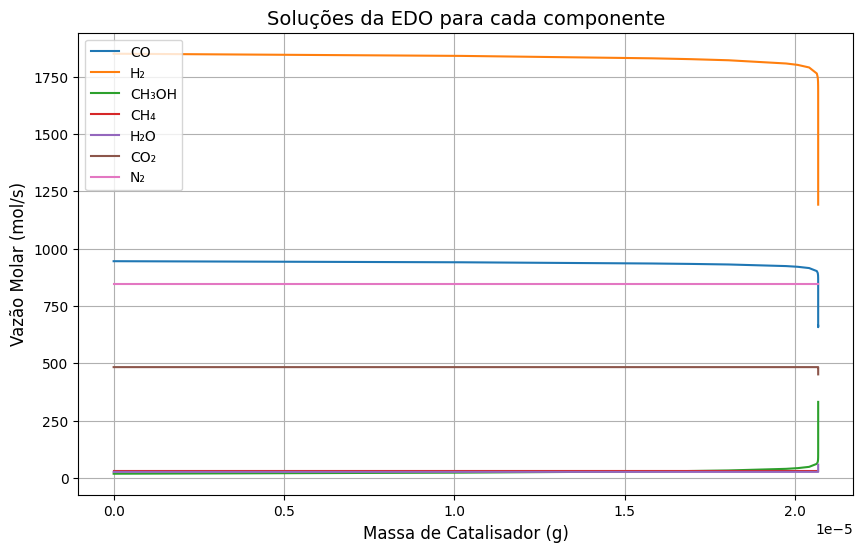

In [12]:
import matplotlib.pyplot as plt

# Extraindo os tempos (ou massas de catalisador)
tempo = solucao.t

# Extraindo as soluções para cada componente
vazao_CO = solucao.y[0]
vazao_H2 = solucao.y[1]
vazao_CH3OH = solucao.y[2]
vazao_CH4 = solucao.y[3]
vazao_H2O = solucao.y[4]
vazao_CO2 = solucao.y[5]
vazao_N2 = solucao.y[6]
temperatura = solucao.y[7]
pressao = solucao.y[8]

# Plotando os resultados
plt.figure(figsize=(10, 6))

plt.plot(tempo, vazao_CO, label="CO")
plt.plot(tempo, vazao_H2, label="H₂")
plt.plot(tempo, vazao_CH3OH, label="CH₃OH")
plt.plot(tempo, vazao_CH4, label="CH₄")
plt.plot(tempo, vazao_H2O, label="H₂O")
plt.plot(tempo, vazao_CO2, label="CO₂")
plt.plot(tempo, vazao_N2, label="N₂")

# Personalização do gráfico
plt.xlabel('Massa de Catalisador (g)', fontsize=12)
plt.ylabel('Vazão Molar (mol/s)', fontsize=12)
plt.title('Soluções da EDO para cada componente', fontsize=14)
plt.legend()
plt.grid(True)

# Mostrar gráfico
plt.show()


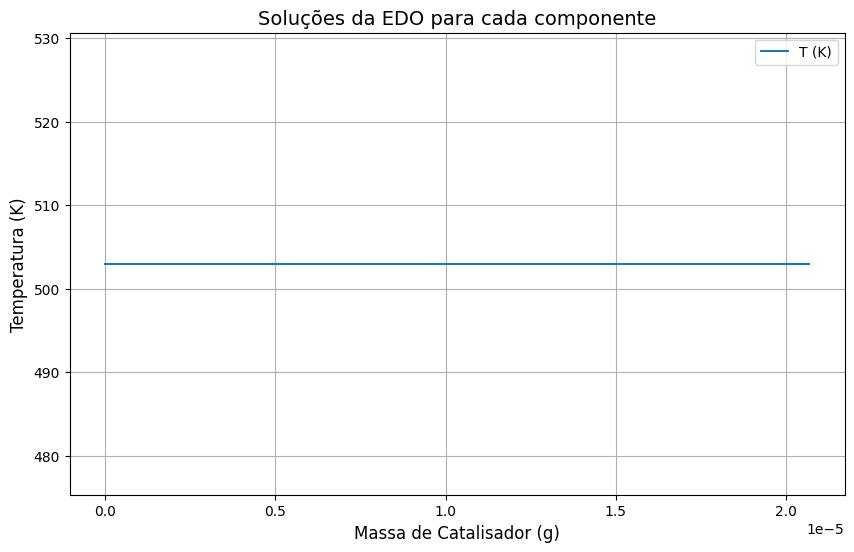

In [13]:
# Plotando os resultados
plt.figure(figsize=(10, 6))

plt.plot(tempo, temperatura, label="T (K)")

# Personalização do gráfico
plt.xlabel('Massa de Catalisador (g)', fontsize=12)
plt.ylabel('Temperatura (K)', fontsize=12)
plt.title('Soluções da EDO para cada componente', fontsize=14)
plt.legend()
plt.grid(True)

# Mostrar gráfico
plt.show()